Dataset:


,StudyHours,Attendance,AssignmentScore,Result
0,1.0,60,45,0
1,1.5,62,50,0
2,2.0,65,52,0
3,2.5,68,55,0
4,3.0,70,60,1
5,3.5,72,65,1
6,4.0,75,68,1
7,4.5,78,72,1
8,5.0,80,75,1
9,5.5,82,78,1


Accuracy: 0.75
Precision: 0.6666666666666666
Recall: 1.0
F1 Score: 0.8


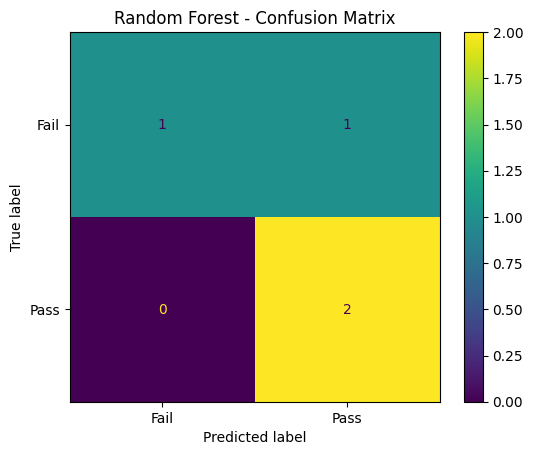

              precision    recall  f1-score   support

        Fail       1.00      0.50      0.67         2
        Pass       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4


Feature Importance:
Attendance         0.382429
AssignmentScore    0.310974
StudyHours         0.306598
dtype: float64


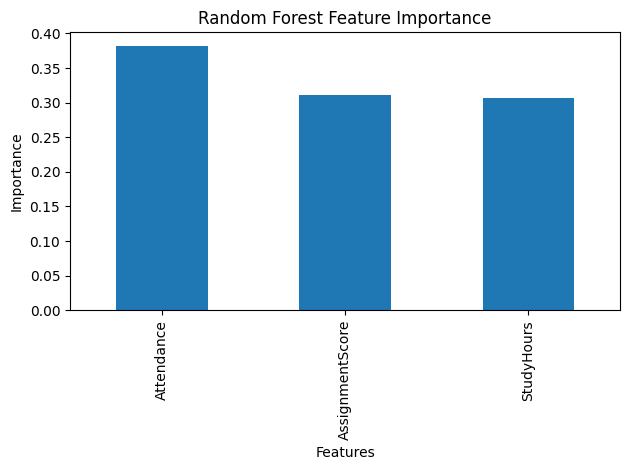

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

data = pd.DataFrame({
    "StudyHours": [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 2.0, 3.0, 4.0],
    "Attendance": [60, 62, 65, 68, 70, 72, 75, 78, 80, 82, 85, 88, 90, 75, 66, 70],
    "AssignmentScore": [45, 50, 52, 55, 60, 65, 68, 72, 75, 78, 82, 85, 88, 58, 54, 62],
    "Result": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1]
})

print("Dataset:")
display(data)

X = data[["StudyHours", "Attendance", "AssignmentScore"]]
y = data["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail", "Pass"]).plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=["Fail", "Pass"], zero_division=0))

importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nFeature Importance:")
print(importance)

importance.plot(kind="bar")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()